# 10 — MLP v5: embeddings + disjoint per-field heads

Current best model. Categorical embeddings **and** 7 separate output heads
(one softmax + cross-entropy per field) instead of a shared vocabulary,
plus continuous-field normalization. Ends with per-field calibration curves.

Evaluation write-up: `evaluations/mlp_v5_disjoint.md` (kept in `scratch/`).

In [1]:
import warnings
from statsbombpy.api_client import NoAuthWarning
from socceraction.data.statsbomb import StatsBombLoader
import pandas as pd
from statsbombpy import sb
import numpy as np
import json
import torch
import torch.nn.functional as F

warnings.filterwarnings("ignore", category=NoAuthWarning)
warnings.filterwarnings("ignore", message="credentials were not supplied")

pd.set_option("display.max_columns", None)  # Show all columns

In [2]:
train = pd.read_csv("data/train_set.csv", index_col=0)
val = pd.read_csv("data/val_set.csv", index_col=0)

## Sentinel remap

`-1` (masked, not yet revealed within the current event) and `-2` (genuinely
absent, e.g. no history at the start of a period) are the only two sentinels
used throughout the dataset. `nn.Embedding`-style lookups can't take negative
indices, so everything that feeds an embedding — and the shared target/output
vocabulary, since `F.one_hot` has the same non-negative-index requirement —
needs remapping into a non-negative space.

One wrinkle: the `target` column already has its `-2`s remapped to `106` in
the source CSV (done upstream in `mlp.ipynb`, before `train_set.csv`/
`val_set.csv` were written), so `target` isn't in the same raw `-1`/`-2`
convention the feature columns are. `remap_sentinel` undoes that `106` first,
then applies one uniform `+2` shift on top — so `-2 -> 0`, `-1 -> 1`, and real
category codes `0.. -> 2..`. One function, used for `target`, the embedded
feature columns, and `masks` (below) — nowhere else needs to know about the
old `106` convention at all.

Continuous columns (`start_x`, `start_y`, `time_elapsed`, `duration`, match
state, etc.) are *not* run through this — a linear layer doesn't care about
sign, so there's no need to touch them, and leaving them alone means one less
thing to keep synchronized between training and sampling.

In [3]:
def remap_sentinel(values):
    """Undo the -2->106 convention baked into `target` (if present), then
    shift everything into a non-negative space: -2 -> 0, -1 -> 1, real
    category codes 0.. -> 2.. . Works on anything array-like (df columns,
    masks lists, tensors)."""
    values = np.asarray(values, dtype=float)
    values = np.where(values == 106, -2.0, values)
    return (values + 2).astype(np.int64)

## Dataset construction

Categorical fields (`event`, `result`, `is_home`) get embedded — `is_home`
is ternary (home/away/boundary), same reasoning as the other two: no
meaningful ordinal relationship between the categories, so it shouldn't be
fed as a raw scalar. Each field's `-1/-2/-3` lag columns share one embedding
table per field (`event`/`event-1`/`event-2`/`event-3` all look up into the
same table), rather than each lag position learning its own independent
representation of what "pass" (or "home") means.

Everything else — spatial/time/duration fields (current + lags) and
match-state fields (`period_id`, `minute`, `second`, goal/card counts) —
stays as raw continuous input, concatenated alongside the embedding outputs.

In [4]:
continuous_fields = ['start_x', 'start_y', 'time_elapsed', 'duration']
match_state_fields = [
    'period_id', 'minute', 'second',
    'home_goal_count', 'away_goal_count',
    'home_red_count', 'away_red_count',
    'home_yellow_count', 'away_yellow_count',
]
embed_fields = ['is_home', 'event', 'result']


def with_lags(fields, n_lags=3):
    cols = list(fields)
    for lag in range(1, n_lags + 1):
        cols += [f'{f}-{lag}' for f in fields]
    return cols


continuous_cols = with_lags(continuous_fields) + match_state_fields
embed_cols = {f: [f] + [f'{f}-{lag}' for lag in range(1, 4)] for f in embed_fields}

## Continuous field normalization

`start_x`/`start_y`/`time_elapsed`/`duration` are fed raw today, and some of
those raw magnitudes (durations up to 68, x/y up to 105) contributed to a
real gradient explosion earlier — large inputs through 3 stacked matmuls
produce large activations and correspondingly large gradients.

Standardize each field (mean/std computed from **train only**, pooled across
the current column + all 3 lags, excluding `-1`/`-2` sentinels so they don't
skew the statistic), then shift to `mean=10, std=1` instead of the usual
`mean=0, std=1`. The shift means real values land safely away from `-1`/`-2`
— confirmed for `duration`, whose most extreme real value would need to be
around `-14` to collide with the sentinel range, well outside where any real
duration can be — so the sentinels can stay exactly as `-1`/`-2`, untouched,
with no separate remapping needed. `period_id`/`minute`/`second`/goal and
card counts are left alone; only the 4 per-event continuous fields go
through this.

In [5]:
def normalize_field(values, mean, std):
    """Standardize real (non-sentinel) values to mean=10, std=1; leaves -1
    (masked) and -2 (no-history) untouched, since real data is shifted
    safely away from them."""
    values = np.asarray(values, dtype=float)
    is_sentinel = (values == -1) | (values == -2)
    return np.where(is_sentinel, values, (values - mean) / std + 10)


continuous_stats = {}

for field in continuous_fields:
    cols = [field] + [f'{field}-{lag}' for lag in range(1, 4)]
    vals = train[cols].values.flatten().astype(float)
    real_vals = vals[(vals != -1) & (vals != -2)]

    continuous_stats[field] = (real_vals.mean(), real_vals.std())

# minute/second are the two match-state fields with genuinely large raw
# magnitude (up to 101/59) -- same risk as the per-event fields, just no
# lag columns to pool across. No -1/-2 sentinels ever occur in either
# (confirmed against the data), but excluding them costs nothing if that
# ever changes.
for field in ['minute', 'second']:
    vals = train[field].values.astype(float)
    real_vals = vals[(vals != -1) & (vals != -2)]

    continuous_stats[field] = (real_vals.mean(), real_vals.std())

continuous_stats

{'start_x': (53.55268451437807, 24.940933159640434),
 'start_y': (34.141970340665786, 20.15318130576347),
 'time_elapsed': (2.9400464379071893, 6.769398249298148),
 'duration': (1.480916550072, 1.4258817513023883),
 'minute': (44.884499208170936, 27.046770791052666),
 'second': (29.284014497471038, 17.358912964627066)}

In [6]:
def build_dataset(df):
    X_cont = df[continuous_cols].values.astype(float).copy()

    for field in continuous_fields:
        mean, std = continuous_stats[field]
        for col in [field] + [f'{field}-{lag}' for lag in range(1, 4)]:
            col_idx = continuous_cols.index(col)
            X_cont[:, col_idx] = normalize_field(X_cont[:, col_idx], mean, std)

    for field in ['minute', 'second']:
        mean, std = continuous_stats[field]
        col_idx = continuous_cols.index(field)
        X_cont[:, col_idx] = normalize_field(X_cont[:, col_idx], mean, std)

    X_cont = torch.tensor(X_cont).float().contiguous()

    X_embed = {}
    for field, cols in embed_cols.items():
        X_embed[field] = torch.tensor(remap_sentinel(df[cols].values)).long().contiguous()

    Y = torch.tensor(remap_sentinel(df['target'].values)).long()
    #Y = F.one_hot(Y, num_classes=108).float()

    return X_cont, X_embed, Y

In [7]:
Xtr_cont, Xtr_embed, Ytr = build_dataset(train)
Xval_cont, Xval_embed, Yval = build_dataset(val)

# vocab size per embedded field, taken from train (val's rarest classes,
# e.g. red_card, may not appear at all in a 10%-of-games val split)
embed_vocab_sizes = {f: int(Xtr_embed[f].max().item()) + 1 for f in embed_fields}
embed_vocab_sizes

{'is_home': 4, 'event': 26, 'result': 8}

## Masks and lookup

`masks` restricts argmax/softmax to a field's valid classes within the shared
108-wide output space, so it needs the same shift as `target` — same helper,
same result. `lookup` (raw code -> human-readable name) is left untouched: its
keys are still the *original* codes, so subtract 2 from a shifted value before
indexing into it.

In [9]:
with open("data/event_masks.json") as f:
    masks = json.load(f)

masks = {col: remap_sentinel(vals).tolist() for col, vals in masks.items()}

with open("data/category_lookup.json") as f:
    lookup = json.load(f)

lookup = {
    col: {int(k): v for k, v in mapping.items()}
    for col, mapping in lookup.items()
}

event_cols = ['is_home', 'event', 'start_x', 'start_y', 'time_elapsed', 'duration', 'result']

output_sizes = {field: len(masks[field]) for field in event_cols}

In [10]:
step_all = torch.tensor(train["step"].values)  # once, up front



In [12]:
g = torch.Generator().manual_seed(42)

n_hidden = 96
emb_size = 3
vocab_size = len(Ytr)
input_size = (emb_size * len(Xtr_embed) * 4) + Xtr_cont[0].shape[0]

C = {}
C["event"] = torch.randn((Xtr_embed["event"].max() + 1, emb_size), generator=g)
C['is_home'] = torch.randn((Xtr_embed["is_home"].max() + 1, emb_size), generator=g)
C['result'] = torch.randn((Xtr_embed["result"].max() + 1, emb_size), generator=g)

W1 = (
    torch.randn((input_size, n_hidden), generator=g) * (2**0.5) / (input_size ** 0.5)
)
b1 = torch.randn(n_hidden, generator=g) * 0
W2 = torch.randn((n_hidden, n_hidden), generator=g) * (2**0.5) / ((W1.shape[1]) ** 0.5)
b2 = torch.randn(n_hidden, generator=g) * 0
W3 = torch.randn((n_hidden, n_hidden), generator=g) * (2**0.5) / ((W2.shape[1]) ** 0.5)
b3 = torch.randn(n_hidden, generator=g) * 0

output_heads = {}

for field in event_cols:
    W4 = torch.randn((n_hidden, output_sizes[field]), generator=g) * 0.001
    b4 = torch.randn(output_sizes[field], generator=g) * 0
    
    output_heads[field] = (W4, b4)

parameters = [C['event'], C['is_home'], C['result'], W1, b1, W2, b2, W3, b3]

for W4, b4 in output_heads.values():
    parameters.append(W4)
    parameters.append(b4)

for p in parameters:
    p.requires_grad = True

lossi = []

In [13]:
local_target_lookups = {}

for field in event_cols:
    field_mask = torch.tensor(masks[field])
    n_classes = len(field_mask)

    pos_lookup = torch.full((108,), -1, dtype=torch.long)
    pos_lookup[field_mask] = torch.arange(n_classes)

    local_target_lookups[field] = pos_lookup

In [14]:
g_eval = torch.Generator().manual_seed(42)
train_eval_ix = torch.randperm(Xtr_cont.shape[0], generator=g_eval)[:Xval_cont.shape[0]]

Xtr_eval_cont = Xtr_cont[train_eval_ix]
Xtr_eval_embed = {key: Xtr_embed[key][train_eval_ix] for key in Xtr_embed}
Ytr_eval = Ytr[train_eval_ix]
step_eval = step_all[train_eval_ix]

In [15]:
max_steps = 1000000
batch_size = 1000
batch_cnt = 100000


def get_lr(step):
    if step < 500000:
        return 0.001
    elif step < 850000:
        return 0.0001
    else:
        return 0.00001


for i in range(max_steps):
    if i % batch_cnt == 0:
        with torch.no_grad():
            train_embs = []

            for key in Xtr_eval_embed:
                emb = C[key][Xtr_eval_embed[key]]
                train_embs.append(emb.view(emb.shape[0], -1))

            h_eval = torch.cat([Xtr_eval_cont, *train_embs], dim=1)

            h_eval = torch.relu(h_eval @ W1 + b1)
            h_eval = torch.relu(h_eval @ W2 + b2)
            h_eval = torch.relu(h_eval @ W3 + b3)

            train_loss = 0

            for idx, field in enumerate(event_cols):
                mask = (idx == step_eval)

                Xr = h_eval[mask]
                Yr = local_target_lookups[field][Ytr_eval[mask]]

                W4, b4 = output_heads[field]
                logits = Xr @ W4 + b4

                train_loss += F.cross_entropy(logits, Yr)

            lossi.append(train_loss.item())

    lr = get_lr(i)
    ix = torch.randint(0, Xtr_cont.shape[0], (batch_size,), generator=g)
    Xb_cont, Yb = Xtr_cont[ix], Ytr[ix]
    step_batch = step_all[ix]

    embs = []

    for key in Xtr_embed: # getting the embeddings
        emb = C[key][Xtr_embed[key][ix]]
        embs.append(emb.view(emb.shape[0], -1))

    Xb = torch.cat([Xb_cont, *embs], dim=1) # full Xb with embeddings
    
    h = torch.relu(Xb @ W1 + b1) # forward pass
    h = torch.relu(h @ W2 + b2)
    h = torch.relu(h @ W3 + b3)
    
    # routing by field
    
    # the idea: go through Xb one field at a time
    # Pass Xb[field] through that output head
    # Calculate loss and accumulate
    
    loss = 0

    for idx, field in enumerate(event_cols):
        mask = (idx == step_batch)
        
        Xr = h[mask]
        Yr = local_target_lookups[field][Yb[mask]]
        W4, b4 = output_heads[field]
        logits = Xr @ W4 + b4
        
        loss += F.cross_entropy(logits, Yr)

    # backward pass

    for p in parameters:
        p.grad = None

    loss.backward()
    #print(loss.item())

    for p in parameters:
        p.data += -lr * p.grad

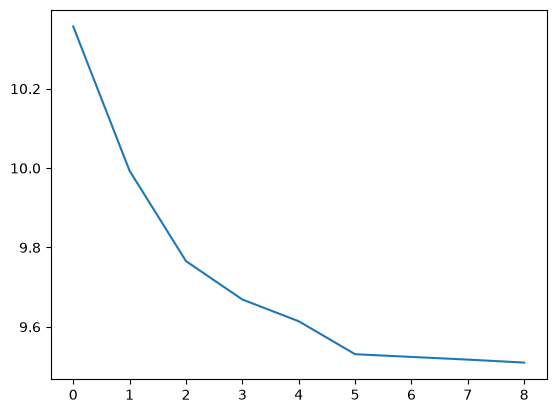

In [17]:
import matplotlib.pyplot as plt

plt.plot(range(len(lossi[1:])), lossi[1:])

In [19]:
checkpoint = {
    "C_event": C["event"],
    "C_is_home": C["is_home"],
    "C_result": C["result"],
    "W1": W1,
    "b1": b1,
    "W2": W2,
    "b2": b2,
    "W3": W3,
    "b3": b3,
    "output_heads": output_heads,
    "lossi": lossi,
    "max_steps": max_steps,
    "seed": 42,
}
torch.save(checkpoint, "data/mlp_embeddings_disjoint_checkpoint.pt")

## Calibration (reliability curves) per categorical field

Same methodology as `mlp_hand.ipynb`'s `field_calibration`/`plot_calibration_grid`
(bin predictions by confidence, check whether empirical accuracy in each bin
matches the average predicted probability), adapted for the disjoint-heads
architecture: each field's head already outputs local (not shared-108-vocab)
logits, so there's no `field_mask` slicing needed before the softmax -- the
head's own output *is* that field's vocabulary.

Loads the trained checkpoint directly rather than reusing the notebook's own
`C`/`W1..b3`/`output_heads` in-memory (those are freshly re-initialized by the
model-init cell above, not the trained weights, unless the training loop was
just run).

In [10]:
ckpt = torch.load("data/mlp_embeddings_disjoint_checkpoint.pt", weights_only=False)
C = {"event": ckpt["C_event"], "is_home": ckpt["C_is_home"], "result": ckpt["C_result"]}
W1, b1 = ckpt["W1"], ckpt["b1"]
W2, b2 = ckpt["W2"], ckpt["b2"]
W3, b3 = ckpt["W3"], ckpt["b3"]
output_heads = ckpt["output_heads"]

In [11]:
import matplotlib.pyplot as plt


@torch.no_grad()
def field_calibration(field, split='val', n_bins=10):
    x_cont, x_embed, y, step = {
        "train": (Xtr_cont, Xtr_embed, Ytr, train['step'].values),
        "val": (Xval_cont, Xval_embed, Yval, val['step'].values),
    }[split]

    step = torch.tensor(step)
    row_mask = step == event_cols.index(field)

    embs = []
    for key in embed_fields:
        emb = C[key][x_embed[key][row_mask]]
        embs.append(emb.view(emb.shape[0], -1))

    h = torch.cat([x_cont[row_mask], *embs], dim=1)
    h = torch.relu(h @ W1 + b1)
    h = torch.relu(h @ W2 + b2)
    h = torch.relu(h @ W3 + b3)

    W4, b4 = output_heads[field]
    logits = h @ W4 + b4
    probs = F.softmax(logits, dim=1).contiguous()

    field_mask = torch.tensor(masks[field])
    n_classes = len(field_mask)
    true_pos = local_target_lookups[field][y[row_mask]]

    bin_edges = torch.linspace(0, 1, n_bins + 1)

    records = []
    curves = {}
    for pos in range(n_classes):
        code_ = field_mask[pos].item() - 2  # undo the +2 shift -> raw category code
        name = str(lookup.get(field, {}).get(code_, code_))

        p = probs[:, pos].contiguous()
        is_true = (true_pos == pos).float()

        bin_ids = torch.bucketize(p, bin_edges[1:-1], right=False)
        bpred, bemp, bcnt = [], [], []
        for b in range(n_bins):
            m = bin_ids == b
            c = m.sum().item()
            if c == 0:
                continue
            bpred.append(p[m].mean().item())
            bemp.append(is_true[m].mean().item())
            bcnt.append(c)
        bpred, bemp, bcnt = torch.tensor(bpred), torch.tensor(bemp), torch.tensor(bcnt)
        ece = (bcnt / bcnt.sum() * (bpred - bemp).abs()).sum().item()

        n_true = int(is_true.sum().item())
        mean_prob_when_true = p[is_true == 1].mean().item() if n_true > 0 else float("nan")

        records.append({
            "class_name": name,
            "n_true": n_true,
            "ece": ece,
            "mean_prob_when_true": mean_prob_when_true,
        })
        curves[name] = (bpred.numpy(), bemp.numpy(), bcnt.numpy())

    summary = pd.DataFrame(records)
    summary["poorly_calibrated"] = (summary["ece"] > 0.02) | (summary["mean_prob_when_true"] < 0.10)
    summary = summary.sort_values("n_true", ascending=False).reset_index(drop=True)

    return summary, curves

In [12]:
def plot_calibration_grid(summary, curves, field):
    n = len(summary)
    ncols = min(5, n)
    nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.6 * nrows), squeeze=False)
    axes = axes.flatten()

    for i, row in summary.iterrows():
        ax = axes[i]
        bpred, bemp, bcnt = curves[row["class_name"]]
        sizes = 20 + 180 * (bcnt / bcnt.max())
        color = "#d62728" if row["poorly_calibrated"] else "#1f77b4"

        ax.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
        ax.plot(bpred, bemp, color=color, alpha=0.4, linewidth=1)
        ax.scatter(bpred, bemp, s=sizes, color=color, alpha=0.8, edgecolor="black", linewidth=0.5)

        ax.set_xlim(-0.02, 1.02)
        ax.set_ylim(-0.02, 1.02)
        ax.set_title(
            f"{row['class_name']}\nn={row['n_true']}, ECE={row['ece']:.3f}, P(true)={row['mean_prob_when_true']:.2f}",
            fontsize=9, color=color, fontweight="bold" if row["poorly_calibrated"] else "normal",
        )
        ax.tick_params(labelsize=7)

    for j in range(n, len(axes)):
        axes[j].axis("off")

    fig.suptitle(
        f"Calibration (reliability) curves per {field} class -- val, sorted by support\n"
        "red = flagged poorly calibrated (ECE>0.02 or mean predicted prob on true class <0.10)",
        fontsize=13,
    )
    fig.tight_layout(rect=[0, 0, 1, 0.96])

,class_name,n_true,ece,mean_prob_when_true,poorly_calibrated
0,home,38730,0.002307,0.920694,False
1,away,35987,0.002277,0.915595,False
2,boundary,114,0.000163,0.949259,False


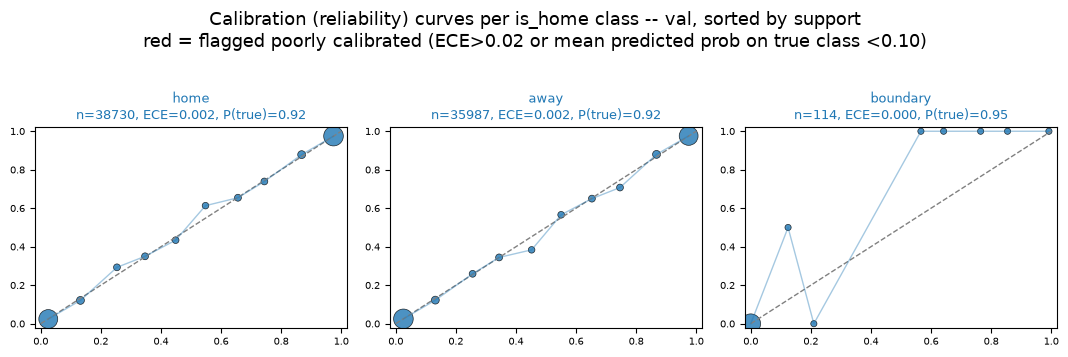

In [13]:
is_home_calib, is_home_calib_curves = field_calibration('is_home', 'val')
plot_calibration_grid(is_home_calib, is_home_calib_curves, 'is_home')
is_home_calib

,class_name,n_true,ece,mean_prob_when_true,poorly_calibrated
0,pass,32212,0.005575,0.728426,False
1,dribble,27957,0.003340,0.768176,False
2,clearance,2231,0.001802,0.324915,False
3,throw_in,1768,0.001500,0.316418,False
4,tackle,1524,0.001227,0.670291,False
5,take_on,1314,0.001144,0.085482,True
6,interception,1313,0.001421,0.253011,False
7,bad_touch,1149,0.001108,0.090562,True
8,shot,1021,0.000885,0.229595,False
9,foul,906,0.000957,0.318974,False


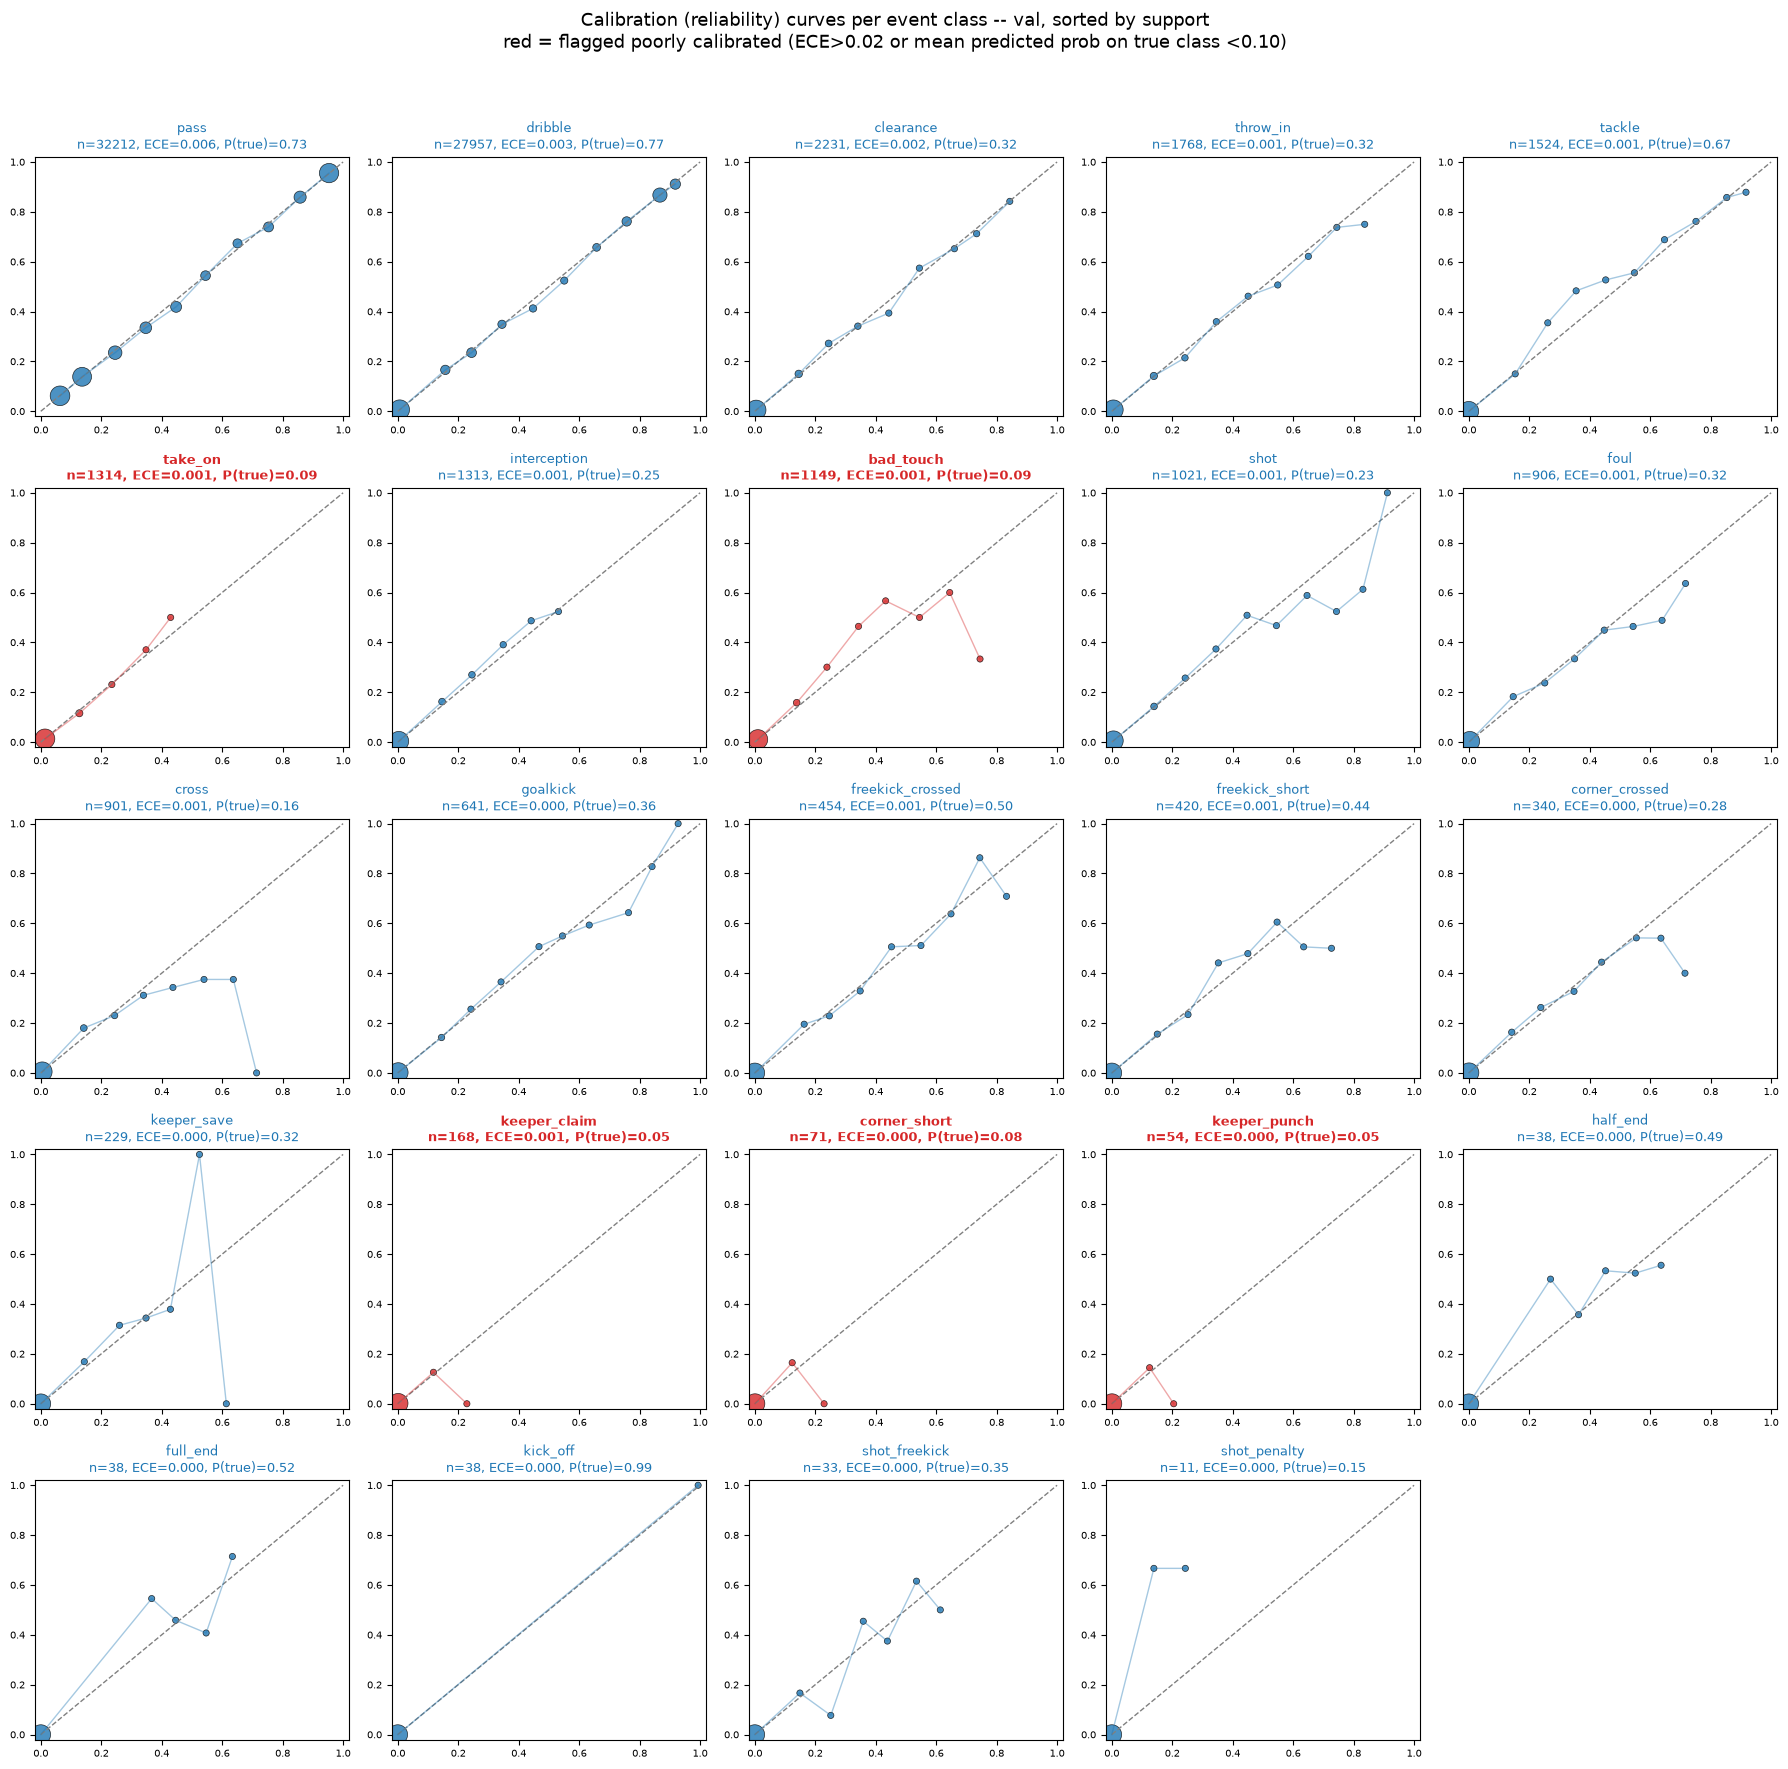

In [14]:
event_calib, event_calib_curves = field_calibration('event', 'val')
plot_calibration_grid(event_calib, event_calib_curves, 'event')
event_calib

,class_name,n_true,ece,mean_prob_when_true,poorly_calibrated
0,success,61859,0.006310,0.898104,False
1,fail,12627,0.006346,0.531592,False
2,offside,135,0.000072,0.005697,True
3,boundary,114,0.000004,0.998829,False
4,yellow_card,93,0.000506,0.118255,False
5,owngoal,3,0.000012,0.006424,True
6,red_card,0,0.000043,NaN,False


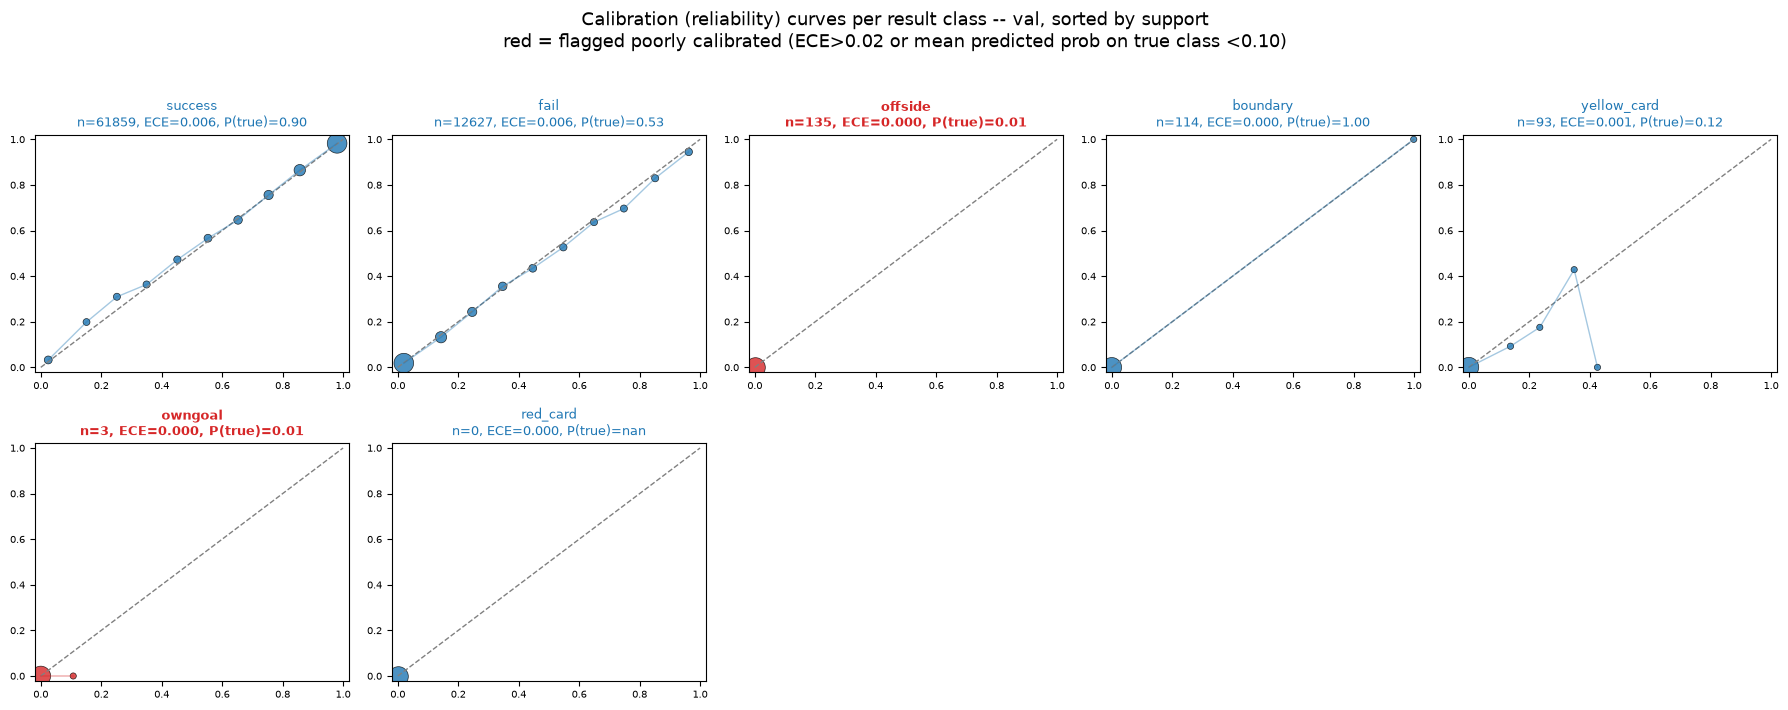

In [15]:
result_calib, result_calib_curves = field_calibration('result', 'val')
plot_calibration_grid(result_calib, result_calib_curves, 'result')
result_calib